# 54 — Pooled screening key plots, common pockets only

Same plots as nb52, but evaluated on **one fixed set of pockets: those present in all 10 conditions**. In nb52 each condition had its own population (e.g. `CCD + Apo pocket` only covered pockets with an apo structure, `CCD + AFDB P2Rank ✓/✗` only those with an AFDB model and a right *and* wrong P2Rank pocket). So some of the gap between two curves could come from *which* pockets each condition covered, not from the condition. Here every curve is computed on exactly the same pockets, so differences between conditions are paired, like-for-like comparisons.

**A pocket is kept only if it is `valid & in_library` in all 10 conditions**, i.e. it has:

* a CCD conformer and a bound conformer (`CCD + Bound pocket`, `Bound + Bound pocket`),
* a holo and an apo structure (`CCD + Holo pocket`, `CCD + Apo pocket`),
* an AFDB model (`CCD + AFDB-translated`),
* a right **and** a wrong P2Rank pocket on both the PDB and the AFDB structure (4 P2Rank conditions),
* a random surface patch (`CCD + Patches`).

nb43 already reduced "≥1 apo / holo / P2Rank pocket / patch" to one representative per pocket, so each pocket has exactly one row per condition. Everything else (cross-dataset dedup, the nested de-leakage ladder, EF pooling, colours, labels) is unchanged from nb52, and all scores are read from the nb43/nb52 caches. Nothing is recomputed.

**The cost is sample size.** Apo and AFDB-P2Rank coverage are the bottlenecks, and the pockets that pass every requirement are mostly well-studied proteins, so the set shrinks quickly under receptor de-leakage (~3,100 at `L0`, ~1,500 at `L1`, ~55 at `L2<0.3`, ~30 at `L3<25`). Plots 2/3 and the paired comparison use a single de-leak level, set by **`PLOT_LEVEL` in the next cell**. Change it there and re-run the notebook. Every plot and table picks it up.

In [1]:
from __future__ import annotations

import json
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from rdkit.DataStructs import BulkTanimotoSimilarity
RDLogger.DisableLog('rdApp.*')

PROJ    = Path.cwd().parent / 'DATA' / 'drugclip'
BENCH   = PROJ / 'RESULTS' / 'benchmark'
NL_ROOT = Path.cwd().parent / 'DATA' / 'natural_ligands'
sys.path.insert(0, str(Path.cwd() / 'natural_ligands_scripts'))
import screening as sc
from ligand_frequency_analysis import train_ligand_freq

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.labelsize': 13, 'xtick.labelsize': 13,
                     'ytick.labelsize': 13})

SHOW_TITLES_LEGENDS = False  # flip to True to bring back titles + legends on plots 1-3

ds_order = ['coach420', 'scpdb', 'holo4k', 'pdbbind2020']
DATASET_PRIORITY = ['coach420', 'scpdb', 'pdbbind2020', 'holo4k']  # nb49 order

# ---- the one knob: de-leak level used by plots 2/3 and the paired comparison ----
# any of: 'L0', 'L1', 'L2<0.7', 'L2<0.5', 'L2<0.3', 'L3<100', 'L3<25', 'L3<5', 'L3=0',
#         'L4<0.9', 'L4<0.7', 'L4<0.5', 'L4<0.3'   (pocket counts per level: see table below)
PLOT_LEVEL = 'L3<25'

N_BOOT = 2000   # bootstrap resamples for the EF@1% confidence intervals
FIG_PREFIX = 'fig54'

## Condition registry

Same 9 CCD-library conditions as nb43 (colours/labels carried over unchanged for continuity with every other pooled plot in this project), plus the new `bound_bound` condition (green — the same colour nb43 used for `source_bound`, since both are the "ceiling" bound-pose condition).

In [2]:
CONDITIONS = [
    ('bound_bound',               '#2CA02C', 'Bound + Bound pocket'),
    ('source_ccd',                '#17BECF', 'CCD + Bound pocket'),
    ('holo_ccd',                  '#FF7F0E', 'CCD + Holo pocket'),
    ('apo_ccd',                   '#1F77B4', 'CCD + Apo pocket'),
    ('afdb_translated_ccd',       '#9467BD', 'CCD + AFDB-translated'),
    ('afdb_p2rank_correct_ccd',   '#D62728', 'CCD + AFDB P2Rank ✓'),
    ('pdb_p2rank_correct_ccd',    '#E377C2', 'CCD + PDB P2Rank ✓'),
    ('afdb_p2rank_wrong_ccd',     '#7F7F7F', 'CCD + AFDB P2Rank ✗'),
    ('pdb_p2rank_wrong_ccd',      '#8C564B', 'CCD + PDB P2Rank ✗'),
    ('patches_ccd',               '#000000', 'CCD + Patches'),
]
COND_IDS    = [c[0] for c in CONDITIONS]
COND_COLOUR = {c[0]: c[1] for c in CONDITIONS}
COND_LABEL  = {c[0]: c[2] for c in CONDITIONS}
CCD_CONDS   = [c for c in COND_IDS if c != 'bound_bound']

## Load the 9 CCD-library conditions (nb43 cache, no recomputation)

In [3]:
raw: dict[str, pd.DataFrame] = {}
for cond in CCD_CONDS:
    frames = [pd.read_parquet(BENCH / f'{ds}_{cond}_screen.parquet') for ds in ds_order]
    raw[cond] = pd.concat(frames, ignore_index=True)
    print(f'{cond:28s} raw n={len(raw[cond]):,}')

source_ccd                   raw n=17,305
holo_ccd                     raw n=17,305
apo_ccd                      raw n=17,305
afdb_translated_ccd          raw n=17,305
afdb_p2rank_correct_ccd      raw n=17,305
pdb_p2rank_correct_ccd       raw n=17,305
afdb_p2rank_wrong_ccd        raw n=17,305
pdb_p2rank_wrong_ccd         raw n=17,305
patches_ccd                  raw n=17,305


## Bound + Bound pocket condition

Loaded from nb52's cache (`RESULTS/benchmark/{ds}_bound_bound_screen.parquet`). The compute branch below is nb52's code, unchanged. It only runs if the cache is missing.

In [4]:
ccd_lib = sc.load_mol_library('CCD')
N_CCD = ccd_lib.emb.shape[0]
ccd_id2row: dict[str, int] = {}
for i, mid in enumerate(ccd_lib.ids):
    ccd_id2row.setdefault(str(mid), i)
print(f'N_CCD = {N_CCD:,}')

cache_paths = {ds: BENCH / f'{ds}_bound_bound_screen.parquet' for ds in ds_order}
if all(p.exists() for p in cache_paths.values()):
    frames = [pd.read_parquet(cache_paths[ds]) for ds in ds_order]
    bound_bound_df = pd.concat(frames, ignore_index=True)
    print(f'Bound + Bound pocket: loaded from cache, n={len(bound_bound_df):,}')
else:
    t0 = time.time()
    frames = []
    for ds in ds_order:
        ps = sc.load_pocket_set(ds)
        bound_lib = sc.load_mol_library(f'bound_{ds}')
        bound_id2row: dict[str, int] = {}
        for i, mid in enumerate(bound_lib.ids):
            bound_id2row.setdefault(str(mid), i)

        P = len(ps.names)
        sims = sc.ensemble_scores(ps, ccd_lib, np.arange(P))  # (P, N_CCD)
        pdb_id_arr = ps.manifest['pdb_id'].to_numpy(dtype=object)

        rows = []
        for i, pid in enumerate(ps.names):
            lig = ps.lig_resname[i]
            brow = bound_id2row.get(pid)
            rec = {'pocket_id': pid, 'lig_resname': lig, 'pdb_id': pdb_id_arr[i],
                   'valid': True, 'condition': 'bound_bound', 'dataset': ds}
            if brow is None:
                rec.update(in_library=False, gt_score=pd.NA, gt_rank=pd.NA)
            else:
                gs = float(sum(ps.emb[k, i, :] @ bound_lib.emb[brow, k, :]
                              for k in range(6)) / 6)
                own_row = ccd_id2row.get(str(lig))
                srow = sims[i]
                beaten = int((srow > gs).sum())
                if own_row is not None and srow[own_row] > gs:
                    beaten -= 1  # own idealised-CCD row excluded from the background
                rec.update(in_library=True, gt_score=gs, gt_rank=beaten + 1)
            rows.append(rec)
        pp = pd.DataFrame(rows)
        pp.to_parquet(cache_paths[ds], index=False)
        frames.append(pp)

        ev = pp[pp['in_library']]
        pct_k = max(1, round(0.01 * N_CCD))
        ef = ((ev['gt_rank'] <= pct_k).mean() * N_CCD / pct_k
              if len(ev) else float('nan'))
        print(f'{ds:12s} bound_bound  P={P:,}  in_library={len(ev):,}  ef@1%~{ef:.1f}')
    bound_bound_df = pd.concat(frames, ignore_index=True)
    print(f'Total wall time: {time.time() - t0:.1f}s')

raw['bound_bound'] = bound_bound_df

N_CCD = 48,999
Bound + Bound pocket: loaded from cache, n=17,305


## Cross-dataset dedup + per-row library size

`dedup_cross_dataset` — identical logic to nb49 / `combined_deleakage_analysis.dedup_cross_dataset`: for a (pdb_id, lig_resname) pair spanning more than one dataset, keep only the row from the first dataset in `DATASET_PRIORITY`. Applied to every condition's own raw frame (all conditions share the same underlying pocket rows, so the same pockets survive in every condition).

Every condition now shares the same CCD-sized background, so `n_lib` is just `N_CCD` throughout (kept as an explicit per-row column rather than a bare constant only so the EF-pooling formula below stays general).

In [5]:
def dedup_cross_dataset(pp: pd.DataFrame,
                        priority: list[str] = DATASET_PRIORITY) -> pd.DataFrame:
    key = pd.Series(list(zip(pp['pdb_id'].str.lower().str.strip(),
                              pp['lig_resname'].str.upper())), index=pp.index)
    winner = pp.groupby(key)['dataset'].transform(
        lambda s: next(d for d in priority if d in set(s)))
    return pp[pp['dataset'] == winner].copy()


pooled: dict[str, pd.DataFrame] = {}
for cond in COND_IDS:
    df = dedup_cross_dataset(raw[cond])
    df['n_lib'] = N_CCD
    df['pct_k'] = np.maximum(1, np.round(0.01 * df['n_lib'])).astype(int)
    pooled[cond] = df
    ev = df['valid'] & df['in_library']
    print(f'{COND_LABEL[cond]:24s} deduped n={len(df):,}   '
          f'valid&in_library n={int(ev.sum()):,}')

Bound + Bound pocket     deduped n=15,640   valid&in_library n=15,640


CCD + Bound pocket       deduped n=15,640   valid&in_library n=15,533


CCD + Holo pocket        deduped n=15,640   valid&in_library n=10,718


CCD + Apo pocket         deduped n=15,640   valid&in_library n=6,867


CCD + AFDB-translated    deduped n=15,640   valid&in_library n=12,930


CCD + AFDB P2Rank ✓      deduped n=15,640   valid&in_library n=8,233


CCD + PDB P2Rank ✓       deduped n=15,640   valid&in_library n=13,327


CCD + AFDB P2Rank ✗      deduped n=15,640   valid&in_library n=8,299


CCD + PDB P2Rank ✗       deduped n=15,640   valid&in_library n=14,542


CCD + Patches            deduped n=15,640   valid&in_library n=15,533


## Restrict every condition to the common pocket set

Intersect the `valid & in_library` pockets of all 10 conditions, keyed by (dataset, pocket_id), after the cross-dataset dedup. Every condition's frame is then cut down to that set and sorted the same way, so row *i* is the same pocket in every condition (asserted below). The paired comparison later relies on this.

The second table shows **what each requirement costs**, in two ways:

* **lost vs full pool**: how many of the deduplicated pockets this condition can't evaluate on its own (full pool − own `valid & in_library`). This is the condition's total loss.
* **lost only to this condition**: pockets that pass every *other* condition but fail this one, i.e. how many pockets would join the common set if this one requirement were dropped. It is much smaller and doesn't add up to the total, because most excluded pockets fail several conditions at once (e.g. no apo *and* no AFDB P2Rank pocket). A 0 means the condition is never the *sole* reason a pocket is excluded. For example, every pocket lacking an AFDB-translated pocket also lacks an AFDB P2Rank pocket, since both need the same AF model.

In [6]:
ev_keys: dict[str, set] = {}
for cond in COND_IDS:
    df = pooled[cond]
    ev = df[df['valid'].astype(bool) & df['in_library'].astype(bool)]
    ev_keys[cond] = set(zip(ev['dataset'], ev['pocket_id']))
COMMON = set.intersection(*ev_keys.values())

POOL_KEYS = set(zip(pooled[COND_IDS[0]]['dataset'], pooled[COND_IDS[0]]['pocket_id']))
N_POOL = len(POOL_KEYS)  # deduplicated pool, before any condition filter
cost = pd.DataFrame({
    'valid & in_library (own)': {COND_LABEL[c]: len(ev_keys[c]) for c in COND_IDS},
    f'lost vs full pool (n={N_POOL:,})': {COND_LABEL[c]: N_POOL - len(ev_keys[c]) for c in COND_IDS},
    'lost only to this condition': {
        COND_LABEL[c]: len(set.intersection(*[ev_keys[o] for o in COND_IDS if o != c]) - ev_keys[c])
        for c in COND_IDS},
})

for cond in COND_IDS:
    df = pooled[cond]
    keep = [k in COMMON for k in zip(df['dataset'], df['pocket_id'])]
    pooled[cond] = (df[keep].sort_values(['dataset', 'pocket_id'])
                    .reset_index(drop=True))

ref_keys = pooled[COND_IDS[0]][['dataset', 'pocket_id']]
for cond in COND_IDS:
    assert pooled[cond][['dataset', 'pocket_id']].equals(ref_keys), cond
    assert (pooled[cond]['valid'].astype(bool) & pooled[cond]['in_library'].astype(bool)).all(), cond

print(f'Common pocket set (all 10 conditions, deduplicated): n = {len(COMMON):,}')
print('by dataset:', ref_keys['dataset'].value_counts().reindex(ds_order).to_dict())
cost

Common pocket set (all 10 conditions, deduplicated): n = 3,089
by dataset: {'coach420': 106, 'scpdb': 611, 'holo4k': 853, 'pdbbind2020': 1519}


,valid & in_library (own),"lost vs full pool (n=15,640)",lost only to this condition
Bound + Bound pocket,15640,0,0
CCD + Bound pocket,15533,107,0
CCD + Holo pocket,10718,4922,136
CCD + Apo pocket,6867,8773,2016
CCD + AFDB-translated,12930,2710,0
CCD + AFDB P2Rank ✓,8233,7407,443
CCD + PDB P2Rank ✓,13327,2313,217
CCD + AFDB P2Rank ✗,8299,7341,576
CCD + PDB P2Rank ✗,14542,1098,94
CCD + Patches,15533,107,0


### Additive breakdown: where the 15,640 → common-set loss comes from

Applied one requirement at a time, greedily: at each step, take the requirement that removes the most pockets *from what's still left*, then repeat on the remainder. Each pocket is charged to the first requirement that removes it, so the `removed` column adds up exactly to the total loss (full pool − common set). The order is set by the data, so a requirement that comes late (e.g. AFDB-translated) can show ~0 just because an earlier one (AFDB P2Rank) already removed the same pockets.

In [7]:
remaining, left, steps = POOL_KEYS, list(COND_IDS), []
while left:
    best = max(left, key=lambda c: len(remaining - ev_keys[c]))
    removed = len(remaining - ev_keys[best])
    remaining = remaining & ev_keys[best]
    steps.append({'requirement': COND_LABEL[best], 'removed': removed,
                  '% of full pool': removed / len(POOL_KEYS) * 100,
                  'pockets left': len(remaining)})
    left.remove(best)
waterfall = pd.DataFrame(steps)
waterfall.index = np.arange(1, len(waterfall) + 1)
assert waterfall['removed'].sum() == len(POOL_KEYS) - len(COMMON)
assert waterfall['pockets left'].iloc[-1] == len(COMMON)
print(f'full pool: {len(POOL_KEYS):,}   common set: {len(COMMON):,}   '
      f'total removed: {waterfall["removed"].sum():,}')
waterfall.round({'% of full pool': 1})

full pool: 15,640   common set: 3,089   total removed: 12,551


,requirement,removed,% of full pool,pockets left
1,CCD + Apo pocket,8773,56.1,6867
2,CCD + AFDB P2Rank ✓,2473,15.8,4394
3,CCD + AFDB P2Rank ✗,778,5.0,3616
4,CCD + PDB P2Rank ✓,295,1.9,3321
5,CCD + Holo pocket,138,0.9,3183
6,CCD + PDB P2Rank ✗,94,0.6,3089
7,Bound + Bound pocket,0,0.0,3089
8,CCD + Bound pocket,0,0.0,3089
9,CCD + AFDB-translated,0,0.0,3089
10,CCD + Patches,0,0.0,3089


## De-leakage level masks

`L0`/`L1`/`L2<t` — PDB-identity and receptor-SI%-to-training, exactly nb43's ladder. `L3<t` / `L3=0` / `L4<t` — new, built inside `L2<0.3`, using ligand training-frequency (`train_ligand_freq`) and nearest-training-ligand ECFP4 Tanimoto. Fingerprints are computed once, only for the CCD codes actually in play (this pool's ligands ∪ the training ligand vocabulary) rather than the full 49k-compound CCD — a few thousand molecules, seconds not minutes.

In [8]:
TRAIN_JSON = NL_ROOT / 'DATA' / 'DRUGCLIP_BIOLIP_TRAINING.json'
SEQ_ID_TSV = NL_ROOT / 'RESULTS' / 'deleakage' / 'pocket_seq_identity.tsv'
CCD_MANIFEST = NL_ROOT / 'RESULTS' / 'components_pub_unimol_manifest.tsv'

folds = json.loads(TRAIN_JSON.read_text())
training_union: set[str] = {x.lower().strip() for v in folds.values() for x in v}

seq_df = pd.read_csv(SEQ_ID_TSV, sep='\t')
pocket_best_pident = dict(zip(seq_df['pocket'], seq_df['best_pident']))

LIG_FREQ = train_ligand_freq().set_index('ligand')['n_pdbs'].to_dict()

# --- nearest-training-ligand Tanimoto (ECFP4/Morgan r=2, 2048 bit) ---
eval_codes: set[str] = set()
for df in pooled.values():
    ev = df[df['valid'] & df['in_library']]
    eval_codes |= set(ev['lig_resname'].str.upper().dropna())
train_codes = {c.upper() for c in LIG_FREQ}
need_codes  = eval_codes | train_codes

man = pd.read_csv(CCD_MANIFEST, sep='\t', dtype=str)
man = man[man['identifier'].str.upper().isin(need_codes)]
fp_map: dict[str, object] = {}
for code_, smi in zip(man['identifier'], man['smiles']):
    if not isinstance(smi, str) or not smi:
        continue
    m = Chem.MolFromSmiles(smi)
    if m is not None:
        fp_map[str(code_).upper()] = AllChem.GetMorganFingerprintAsBitVect(m, 2, 2048)

train_fps = [fp_map[c] for c in train_codes if c in fp_map]
t0 = time.time()
NN_TS: dict[str, float] = {}
for c in eval_codes:
    if c not in fp_map:
        continue
    sims = BulkTanimotoSimilarity(fp_map[c], train_fps)
    NN_TS[c] = max(sims) if sims else 0.0
print(f'nearest-training-ligand Tanimoto: {len(NN_TS):,} eval ligand codes '
      f'({len(train_fps):,} training fps) in {time.time() - t0:.1f}s')

DE_LEVELS = ['L0', 'L1', 'L2<0.7', 'L2<0.5', 'L2<0.3',
             'L3<100', 'L3<25', 'L3<5', 'L3=0',
             'L4<0.9', 'L4<0.7', 'L4<0.5', 'L4<0.3']


def format_level_label(level: str) -> str:
    """'L2<0.7' -> 'L$_2$ < 0.7'; 'L3=0' -> 'L$_3$ = 0'; 'L0' -> 'L$_0$' — stage
    number subscripted, a space added either side of the comparison operator."""
    m = re.match(r'L(\d)(<|=)?(.*)', level)
    stage, op, rest = m.group(1), m.group(2), m.group(3)
    label = f'L$_{{{stage}}}$'
    if op:
        label += f' {op} {rest}'
    return label


DE_LEVELS_FMT = [format_level_label(lv) for lv in DE_LEVELS]


def get_level_mask(df: pd.DataFrame, level: str) -> np.ndarray:
    mask = np.ones(len(df), dtype=bool)
    if level == 'L0':
        return mask
    in_train = df['pdb_id'].str.lower().str.strip().isin(training_union).to_numpy()
    mask &= ~in_train
    if level == 'L1':
        return mask
    bid = df['pocket_id'].map(pocket_best_pident).fillna(0.0).to_numpy()
    if level.startswith('L2<'):
        mask &= (bid < float(level.split('<')[1]))
        return mask
    mask &= (bid < 0.3)  # every L3/L4 rung lives inside L2<0.3
    lig_freq = df['lig_resname'].str.upper().map(LIG_FREQ).fillna(0).astype(int).to_numpy()
    if level.startswith('L3<'):
        mask &= (lig_freq < float(level.split('<')[1]))
        return mask
    mask &= (lig_freq == 0)
    if level == 'L3=0':
        return mask
    # L4<t: unseen ligand codes (no fingerprint) can't be shown novel -> excluded
    nn_ts = df['lig_resname'].str.upper().map(NN_TS).fillna(1.0).to_numpy()
    mask &= (nn_ts < float(level.split('<')[1]))
    return mask

nearest-training-ligand Tanimoto: 2,007 eval ligand codes (22,774 training fps) in 10.0s


### Sanity check: is this really nested?

In [9]:
check_df = pooled['source_ccd']
check_ev = (check_df['valid'] & check_df['in_library']).to_numpy()
prev = None
for lv in DE_LEVELS:
    cur = get_level_mask(check_df, lv) & check_ev
    if prev is not None:
        assert np.all(cur <= prev), f'{lv} is NOT a subset of the previous level!'
    prev = cur
print('OK — every level is a strict subset of the one before it '
      "(checked on the common set).")

OK — every level is a strict subset of the one before it (checked on the common set).


## De-leakage ladder: how the common set shrinks

Every condition now has the same pockets, so one count per level covers all of them (asserted). Compare with nb52's table, where each condition had its own count.

In [10]:
level_n = {}
for level in DE_LEVELS:
    ns = {int(get_level_mask(pooled[c], level).sum()) for c in COND_IDS}
    assert len(ns) == 1, (level, ns)
    level_n[level] = ns.pop()
level_counts = pd.DataFrame({'n pockets (every condition)': level_n})
level_counts.index.name = 'level'
print(f'PLOT_LEVEL = {PLOT_LEVEL!r}  ->  n = {level_n[PLOT_LEVEL]:,} pockets')
level_counts

PLOT_LEVEL = 'L3<25'  ->  n = 30 pockets


,n pockets (every condition)
level,
L0,3089
L1,1498
L2<0.7,199
L2<0.5,129
L2<0.3,55
L3<100,37
L3<25,30
L3<5,27
L3=0,19


## Plot 1 — EF@1% vs de-leakage level (pooled)

One pooled population per level (not per dataset). EF is pooled as **total hits / total expected-random-hits** (`Σ hit / Σ pct_k/n_lib`) rather than a naive average of per-pocket rates — this is equivalent to the ordinary EF formula since every condition now shares the same CCD-sized background (`n_lib` constant), and stays correct as a general pooling rule if that ever changes again.

Past `L2<0.5` the common set gets thin (see the table above). Rather than just saying so in prose, **each line switches from solid to dashed right after its last level with ≥100 pooled pockets**. With a common pocket set, every line now goes dashed at the same level.

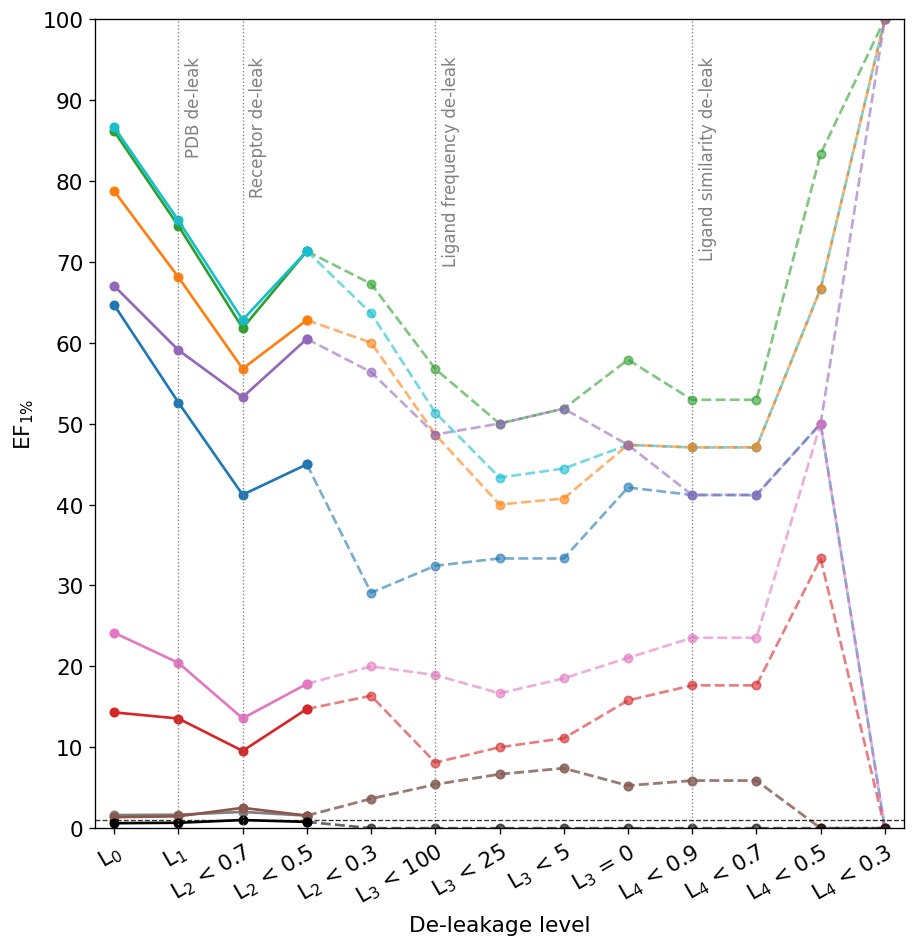


—— EF@1% by level (pooled) ——


level,L0,L1,L2<0.7,L2<0.5,L2<0.3,L3<100,L3<25,L3<5,L3=0,L4<0.9,L4<0.7,L4<0.5,L4<0.3
condition,,,,,,,,,,,,,
Bound + Bound pocket,86.1,74.4,61.8,71.3,67.3,56.8,50.0,51.9,57.9,52.9,52.9,83.3,100.0
CCD + Bound pocket,86.6,75.1,62.8,71.3,63.6,51.4,43.3,44.4,47.4,47.1,47.1,66.7,100.0
CCD + Holo pocket,78.7,68.1,56.8,62.8,60.0,48.6,40.0,40.7,47.4,47.1,47.1,66.7,100.0
CCD + Apo pocket,64.6,52.6,41.2,45.0,29.1,32.4,33.3,33.3,42.1,41.2,41.2,50.0,0.0
CCD + AFDB-translated,67.0,59.1,53.3,60.5,56.4,48.6,50.0,51.9,47.4,41.2,41.2,50.0,100.0
CCD + AFDB P2Rank ✓,14.3,13.6,9.5,14.7,16.4,8.1,10.0,11.1,15.8,17.6,17.6,33.3,0.0
CCD + PDB P2Rank ✓,24.1,20.4,13.6,17.8,20.0,18.9,16.7,18.5,21.1,23.5,23.5,50.0,0.0
CCD + AFDB P2Rank ✗,1.6,1.7,2.0,1.6,3.6,5.4,6.7,7.4,5.3,5.9,5.9,0.0,0.0
CCD + PDB P2Rank ✗,1.4,1.5,2.5,1.6,3.6,5.4,6.7,7.4,5.3,5.9,5.9,0.0,0.0


In [11]:
def pooled_ef1pct(df: pd.DataFrame, level: str) -> tuple[float, int]:
    ev = df[get_level_mask(df, level) & df['valid'] & df['in_library']].copy()
    if len(ev) == 0:
        return float('nan'), 0
    ev['hit'] = (ev['gt_rank'] <= ev['pct_k']).astype(float)
    frac = ev['pct_k'] / ev['n_lib']
    ef = ev['hit'].sum() / frac.sum()
    return ef, len(ev)


ef_rows = []
for cond in COND_IDS:
    for level in DE_LEVELS:
        ef, n = pooled_ef1pct(pooled[cond], level)
        ef_rows.append({'condition': cond, 'level': level, 'ef@1%': ef, 'n': n})
ef_summary = pd.DataFrame(ef_rows)

MIN_RELIABLE_N = 100

fig, ax = plt.subplots(figsize=(8, 8))
x_all = np.arange(len(DE_LEVELS))
for cond in COND_IDS:
    sub = ef_summary[ef_summary['condition'] == cond].set_index('level').reindex(DE_LEVELS)
    y, n = sub['ef@1%'].to_numpy(), sub['n'].to_numpy()
    reliable = np.where(n >= MIN_RELIABLE_N)[0]
    k = reliable.max() if len(reliable) else 0
    color = COND_COLOUR[cond]
    ax.plot(x_all[:k + 1], y[:k + 1], marker='o', ms=5, lw=1.6,
            color=color, label=COND_LABEL[cond])
    ax.plot(x_all[k:], y[k:], marker='o', ms=5, lw=1.6, ls='--',
            color=color, alpha=0.6)
ax.set_xticks(x_all)
ax.set_xticklabels(DE_LEVELS_FMT, rotation=30, ha='right',
                   rotation_mode='anchor', fontsize=13)
ax.set_xlim(x_all[0] - 0.3, x_all[-1] + 0.3)
ax.set_yticks(range(0, 101, 10)); ax.set_ylim(0, 100)
# vertical markers sit ON the level where each de-leak stage begins, not between points.
# 6 trailing spaces push the visible word down, off the top axis border (rotation=90 +
# va='top' reads bottom-to-top, so trailing chars land nearest the border).
for xpos, txt in [(DE_LEVELS.index('L1'), 'PDB de-leak       '),
                  (DE_LEVELS.index('L2<0.7'), 'Receptor de-leak       '),
                  (DE_LEVELS.index('L3<100'), 'Ligand frequency de-leak       '),
                  (DE_LEVELS.index('L4<0.9'), 'Ligand similarity de-leak       ')]:
    ax.axvline(xpos, color='grey', lw=0.8, ls=':')
    ax.annotate(txt, (xpos + 0.1, ax.get_ylim()[1]), fontsize=10, color='grey',
                rotation=90, va='top', ha='left')
ax.axhline(1.0, ls='--', lw=0.8, color='black', alpha=0.8)
ax.set_ylabel(r'EF$_{1\%}$', fontsize=13); ax.set_xlabel('De-leakage level', fontsize=13)
if SHOW_TITLES_LEGENDS:
    ax.set_title(r'Pooled EF$_{1\%}$ vs de-leakage level (common pockets, de-duplicated)')
    # Legend sits outside the axes so it never covers the 'Ligand similarity de-leak' marker
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
ax.set_box_aspect(1)
fig.tight_layout()
fig.savefig(BENCH / f'{FIG_PREFIX}_ef1pct_vs_deleak_common.png', dpi=600, bbox_inches='tight')
plt.show()

print(f'\n—— EF@1% by level (pooled) ——')
display(ef_summary.pivot(index='condition', columns='level', values='ef@1%')
        .reindex(COND_IDS).reindex(columns=DE_LEVELS).round(1)
        .rename(index=COND_LABEL))

## Plot 2 — Score-threshold survival (common pockets, at `PLOT_LEVEL`)

% of common pockets whose ensemble cosine score is ≥ τ, for τ swept 0 → 1. The same pockets are behind every curve.

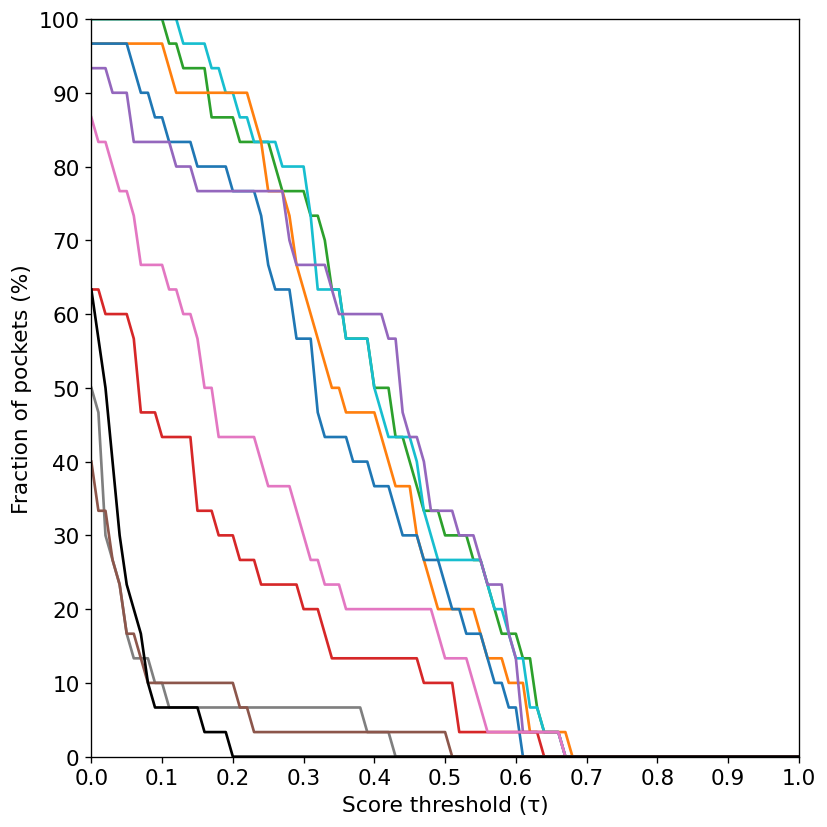

In [12]:
thresholds = np.linspace(0, 1, 101)

fig, ax = plt.subplots(figsize=(7, 7))
for cond in COND_IDS:
    df  = pooled[cond]
    ev  = df[get_level_mask(df, PLOT_LEVEL) & df['valid'] & df['in_library']]
    vals = ev['gt_score'].dropna().to_numpy(dtype=float)
    if len(vals) == 0:
        continue
    surv = np.array([(vals >= t).mean() * 100 for t in thresholds])
    ax.plot(thresholds, surv, color=COND_COLOUR[cond], lw=1.6,
            label=f'{COND_LABEL[cond]} (n={len(vals):,})')
ax.set_xlim(0, 1); ax.set_ylim(0, 100)
ax.set_xticks(np.arange(0, 1.01, 0.1)); ax.set_yticks(range(0, 101, 10))
ax.set_xlabel('Score threshold (τ)'); ax.set_ylabel('Fraction of pockets (%)')
if SHOW_TITLES_LEGENDS:
    ax.set_title(f'Common pockets, {PLOT_LEVEL} — score-threshold survival')
    ax.legend(fontsize=7, loc='upper right')
fig.tight_layout()
fig.savefig(BENCH / f'{FIG_PREFIX}_score_survival_common.png', dpi=600, bbox_inches='tight')
plt.show()

### Bound vs idealised CCD conformer, same pockets

Same check as nb52, on the common set at `PLOT_LEVEL`.

In [13]:
_lv  = get_level_mask(pooled['source_ccd'], PLOT_LEVEL)
_ccd = pooled['source_ccd'].loc[_lv, 'gt_score'].astype(float).to_numpy()
_bb  = pooled['bound_bound'].loc[_lv, 'gt_score'].astype(float).to_numpy()
print(f'{PLOT_LEVEL}: n = {len(_ccd):,} pockets')
print(f'score correlation (Pearson): {np.corrcoef(_ccd, _bb)[0, 1]:.3f}')
print(f'mean score   — idealised CCD conformer: {_ccd.mean():.3f}   bound conformer: {_bb.mean():.3f}')
print(f'median score — idealised CCD conformer: {np.median(_ccd):.3f}   bound conformer: {np.median(_bb):.3f}')
print(f'fraction of pockets where the idealised CCD conformer outscores the bound conformer: '
      f'{(_ccd > _bb).mean() * 100:.1f}%')

L3<25: n = 30 pockets
score correlation (Pearson): 0.973
mean score   — idealised CCD conformer: 0.408   bound conformer: 0.406
median score — idealised CCD conformer: 0.401   bound conformer: 0.411
fraction of pockets where the idealised CCD conformer outscores the bound conformer: 63.3%


## Plot 3 — Ground-truth rank ECDF (common pockets, at `PLOT_LEVEL`)

Log-scale ECDF of `gt_rank` against the full CCD library.

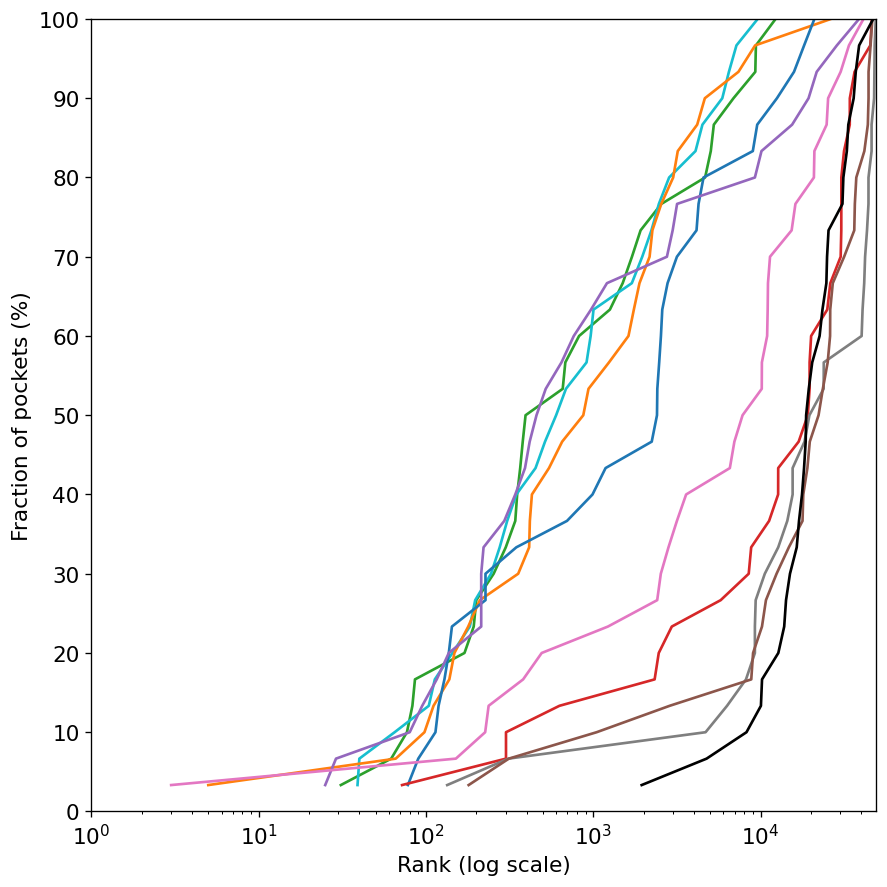

In [14]:
rank_max = N_CCD

fig, ax = plt.subplots(figsize=(7.5, 7.5))
for cond in COND_IDS:
    df = pooled[cond]
    ev = df[get_level_mask(df, PLOT_LEVEL) & df['valid'] & df['in_library']]
    ranks = np.sort(ev['gt_rank'].dropna().astype(int).to_numpy())
    if len(ranks) == 0:
        continue
    cdf = 100 * np.arange(1, len(ranks) + 1) / len(ranks)
    ax.plot(ranks, cdf, lw=1.6, color=COND_COLOUR[cond],
            label=f'{COND_LABEL[cond]} (n={len(ranks):,})')

ax.set_xscale('log'); ax.set_xlim(1, rank_max); ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 10))
ax.set_xlabel('Rank (log scale)'); ax.set_ylabel('Fraction of pockets (%)')
if SHOW_TITLES_LEGENDS:
    ax.set_title(f'Common pockets, {PLOT_LEVEL} — ground-truth rank ECDF')
    ax.legend(fontsize=7, loc='upper left')
fig.tight_layout()
fig.savefig(BENCH / f'{FIG_PREFIX}_rank_ecdf_common.png', dpi=600, bbox_inches='tight')
plt.show()

---
## Notes

* **Figures written to `RESULTS/benchmark/`:** `fig54_ef1pct_vs_deleak_common.png`, `fig54_score_survival_common.png`, `fig54_rank_ecdf_common.png`, `fig54_ef1pct_ci_common.png`, `fig54_score_survival_ladder_panel_common.png`, `fig54_rank_ecdf_ladder_panel_common.png`. No new caches; everything is read from nb43/nb52's parquet files.
* **To change the level** for plots 2/3 and the paired comparison, edit `PLOT_LEVEL` in the second cell and re-run all. Plots 1, 4 and 5 sweep the whole ladder and don't depend on it.